In [1]:
import numpy as np
# إصلاح للتوافق مع الكود القديم الذي يستخدم np.bool
if not hasattr(np, 'bool'):
    np.bool = bool

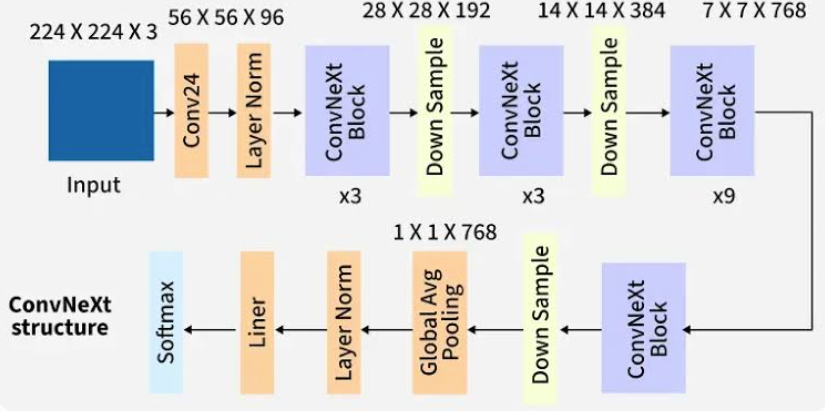

In [2]:
import os
import random
import numpy as np
import pandas as pd
import cv2
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.efficientnet import preprocess_input as ef_preprocess

# إصلاح توافقية np.bool مع NumPy 2.x
if not hasattr(np, 'bool'):
    np.bool = bool

import albumentations as A

# ================================================================
# 1. Parameter Settings
# ================================================================
DATASET_PATH_1 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
DATASET_PATH_2 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2'
METADATA_CSV = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv'

IMG_SIZE = 224
BATCH_SIZE = 32
RANDOM_STATE = 42
EPOCHS = 30

TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-6

# Set random seed for reproducibility
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ================================================================
# 2. Load Metadata and Image Paths
# ================================================================
meta_df = pd.read_csv(METADATA_CSV)
imageid_to_label = dict(zip(meta_df['image_id'], meta_df['dx']))

image_files_1 = sorted(os.listdir(DATASET_PATH_1))
image_files_2 = sorted(os.listdir(DATASET_PATH_2))
all_image_files = image_files_1 + image_files_2

rows = []
for fname in tqdm(all_image_files, desc='Listing images'):
    image_id = os.path.splitext(fname)[0]
    label = imageid_to_label.get(image_id)
    if label is None: 
        continue
    if fname in image_files_1:
        full = os.path.join(DATASET_PATH_1, fname)
    else:
        full = os.path.join(DATASET_PATH_2, fname)
    rows.append((full, label))

df = pd.DataFrame(rows, columns=['path', 'label'])
print("Total images found:", len(df))

# Encode string labels to integers
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))

# ================================================================
# 3. Stratified Dataset Split (70% Train / 15% Val / 15% Test)
# ================================================================
train_and_val, test_df = train_test_split(
    df, test_size=TEST_RATIO, stratify=df['label_enc'], random_state=RANDOM_STATE
)
relative_val_ratio = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_df, val_df = train_test_split(
    train_and_val, test_size=relative_val_ratio, stratify=train_and_val['label_enc'], random_state=RANDOM_STATE
)

print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")

# ================================================================
# 4. Image Preprocessing Transformation (No Augmentation)
# ================================================================
base_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE)
])

def load_image(path, transform=None):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if transform:
        img = transform(image=img)["image"]
    else:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return ef_preprocess(img.astype(np.float32))

# ================================================================
# 5. Data Generator Class
# ================================================================
class ConvNeXtOnlyGenerator(tf.keras.utils.Sequence):
    def __init__(self, df, batch_size=32, transform=None, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.transform = transform
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_paths = self.df.loc[batch_idx, "path"].values
        batch_labels = self.df.loc[batch_idx, "label_enc"].values
        
        imgs = [load_image(path, transform=self.transform) for path in batch_paths]
        imgs = np.stack(imgs, axis=0)
        y = tf.keras.utils.to_categorical(batch_labels, num_classes=num_classes)
        return imgs, y

train_gen = ConvNeXtOnlyGenerator(train_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=True)
val_gen = ConvNeXtOnlyGenerator(val_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)
test_gen = ConvNeXtOnlyGenerator(test_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)

# ================================================================
# 6. Build ConvNeXt Only Model
# ================================================================
def build_convnext_only(num_classes, img_size=224):
    img_input = layers.Input(shape=(img_size, img_size, 3), name='image_input')
    
    # ConvNeXt-Tiny Backbone
    base_model = ConvNeXtTiny(include_top=False, input_tensor=img_input, weights='imagenet')
    
    # Classification Head
    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(num_classes, activation='softmax', name='output')(x)
    
    model = models.Model(inputs=img_input, outputs=out, name='Experiment1_ConvNeXt_Only')
    return model, base_model

model, base_model = build_convnext_only(num_classes, IMG_SIZE)

# Unfreeze backbone layers for full fine-tuning
for layer in base_model.layers:
    layer.trainable = True

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ================================================================
# 7. Model Training
# ================================================================
checkpoint_path = "exp1_convnext_only_best.h5"
cb = [
    callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

print("\n>>> Starting Experiment 1: ConvNeXt Only Training <<<\n")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=cb
)

# ================================================================
# 8. Evaluation on Test Set
# ================================================================
print("\n>>> Evaluating Best Model on Test Set <<<")
model.load_weights(checkpoint_path)

y_true = []
y_pred_probs = []

for i in range(len(test_gen)):
    imgs, y_batch = test_gen[i]
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(y_batch, axis=1))
    y_pred_probs.extend(preds)

y_pred = np.argmax(y_pred_probs, axis=1)

print("\n--- Test Accuracy ---")
test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=le.classes_))

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_true, y_pred))

Listing images: 100%|██████████| 10015/10015 [00:00<00:00, 19543.36it/s]


Total images found: 10015
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Train samples: 7009 | Val samples: 1503 | Test samples: 1503


I0000 00:00:1788797893.807298      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788797893.810900      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Experiment1_ConvNeXt_Only"

...


Epoch 6: finished saving model to exp1_convnext_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 173s 787ms/step - accuracy: 0.9599 - loss: 0.1166 - val_accuracy: 0.8609 - val_loss: 0.4821 - learning_rate: 1.0000e-04
Epoch 7/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 731ms/step - accuracy: 0.9802 - loss: 0.0599
Epoch 7: val_accuracy improved from 0.86094 to 0.87226, saving model to exp1_convnext_only_best.h5



Epoch 7: finished saving model to exp1_convnext_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 174s 792ms/step - accuracy: 0.9796 - loss: 0.0589 - val_accuracy: 0.8723 - val_loss: 0.6236 - learning_rate: 1.0000e-04
Epoch 8/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 732ms/step - accuracy: 0.9828 - loss: 0.0554
Epoch 8: val_accuracy did not improve from 0.87226

Epoch 8: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
220/220 ━━━━━━━━━━━━━━━━━━━━ 174s 788ms/step - accuracy: 0.9857 - loss: 0.0446 - val_accuracy: 0.8689 - val_loss: 0.5927 - learning_rate: 1.0000e-04
Epoch 9/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 730ms/step - accuracy: 0.9979 - loss: 0.0110
Epoch 9: val_accuracy improved from 0.87226 to 0.88157, saving model to exp1_convnext_only_best.h5



Epoch 9: finished saving model to exp1_convnext_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 174s 790ms/step - accuracy: 0.9961 - loss: 0.0144 - val_accuracy: 0.8816 - val_loss: 0.5854 - learning_rate: 5.0000e-05
Epoch 10/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 732ms/step - accuracy: 0.9971 - loss: 0.0087
Epoch 10: val_accuracy did not improve from 0.88157
220/220 ━━━━━━━━━━━━━━━━━━━━ 174s 789ms/step - accuracy: 0.9984 - loss: 0.0064 - val_accuracy: 0.8816 - val_loss: 0.5218 - learning_rate: 5.0000e-05
Epoch 11/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 732ms/step - accuracy: 0.9983 - loss: 0.0061
Epoch 11: val_accuracy improved from 0.88157 to 0.88689, saving model to exp1_convnext_only_best.h5



Epoch 11: finished saving model to exp1_convnext_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 175s 795ms/step - accuracy: 0.9984 - loss: 0.0055 - val_accuracy: 0.8869 - val_loss: 0.5311 - learning_rate: 5.0000e-05
Epoch 12/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 732ms/step - accuracy: 0.9997 - loss: 0.0031
Epoch 12: val_accuracy did not improve from 0.88689
220/220 ━━━━━━━━━━━━━━━━━━━━ 174s 790ms/step - accuracy: 0.9994 - loss: 0.0036 - val_accuracy: 0.8556 - val_loss: 0.7254 - learning_rate: 5.0000e-05
Epoch 13/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 732ms/step - accuracy: 0.9980 - loss: 0.0065
Epoch 13: val_accuracy did not improve from 0.88689

Epoch 13: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
220/220 ━━━━━━━━━━━━━━━━━━━━ 173s 786ms/step - accuracy: 0.9976 - loss: 0.0079 - val_accuracy: 0.8769 - val_loss: 0.6126 - learning_rate: 5.0000e-05
Epoch 14/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 730ms/step - accuracy: 0.9998 - loss: 0.0023
Epoch 14: val_accuracy improved from 0.88


Epoch 14: finished saving model to exp1_convnext_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 174s 789ms/step - accuracy: 0.9999 - loss: 0.0021 - val_accuracy: 0.8909 - val_loss: 0.5565 - learning_rate: 2.5000e-05
Epoch 15/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 730ms/step - accuracy: 0.9996 - loss: 0.0023
Epoch 15: val_accuracy did not improve from 0.89088
220/220 ━━━━━━━━━━━━━━━━━━━━ 173s 784ms/step - accuracy: 0.9997 - loss: 0.0021 - val_accuracy: 0.8789 - val_loss: 0.6109 - learning_rate: 2.5000e-05
Epoch 16/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 730ms/step - accuracy: 1.0000 - loss: 0.0016
Epoch 16: val_accuracy did not improve from 0.89088
220/220 ━━━━━━━━━━━━━━━━━━━━ 174s 790ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.8889 - val_loss: 0.5604 - learning_rate: 2.5000e-05
Epoch 17/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 732ms/step - accuracy: 0.9999 - loss: 0.0017
Epoch 17: val_accuracy did not improve from 0.89088
220/220 ━━━━━━━━━━━━━━━━━━━━ 173s 786ms/step - accuracy: 0.9997 - l

Test Accuracy: 87.69%
Classification Report:
               precision    recall  f1-score   support

       akiec     0.6889    0.6327    0.6596        49
         bcc     0.8696    0.7792    0.8219        77
         bkl     0.7730    0.7636    0.7683       165
          df     0.7857    0.6471    0.7097        17
         mel     0.7727    0.6108    0.6823       167
          nv     0.9192    0.9612    0.9397      1006
        vasc     0.7500    0.9545    0.8400        22

    accuracy                         0.8769      1503
   macro avg     0.7942    0.7642    0.7745      1503
weighted avg     0.8728    0.8769    0.8731      1503



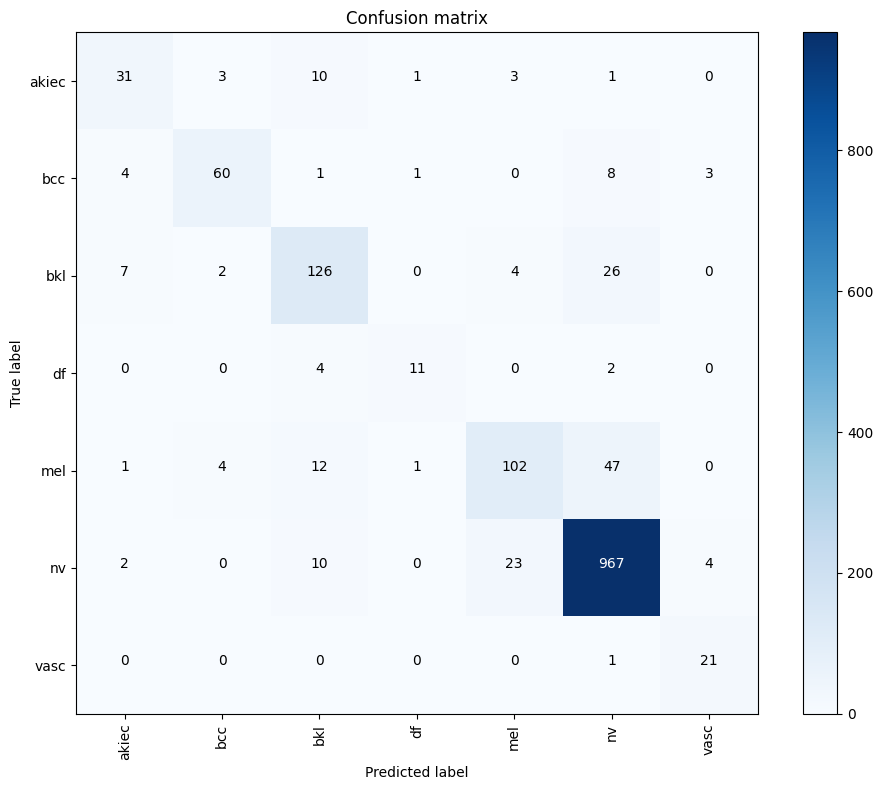

In [3]:
# ================================================================
# Evaluation - Safe Version
# ================================================================
import itertools
def get_preds_safe(generator):
    """Collect predictions from generator safely"""
    preds, labels = [], []
    n_batches = len(generator)
    
    for i in range(n_batches):
        try:
            X, y = generator[i]
            if isinstance(X, tuple):
                p = model.predict(X, verbose=0)
            else:
                p = model.predict(X, verbose=0)
            preds.append(p)
            labels.append(y)
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not preds:
        return np.array([]), np.array([])
    
    return np.vstack(preds), np.vstack(labels)

preds, true = get_preds_safe(test_gen)
pred_labels = np.argmax(preds, axis=1)
true_labels = np.argmax(true, axis=1)

acc = accuracy_score(true_labels, pred_labels)
print(f"Test Accuracy: {acc*100:.2f}%")
print("Classification Report:\n", classification_report(true_labels, pred_labels, target_names=le.classes_, digits=4))

cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(10,8))
plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.colorbar()
plt.xticks(np.arange(len(le.classes_)), le.classes_, rotation=90)
plt.yticks(np.arange(len(le.classes_)), le.classes_)
thresh = cm.max() / 2
for i,j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j,i,cm[i,j], ha="center", color="white" if cm[i,j]>thresh else "black")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()


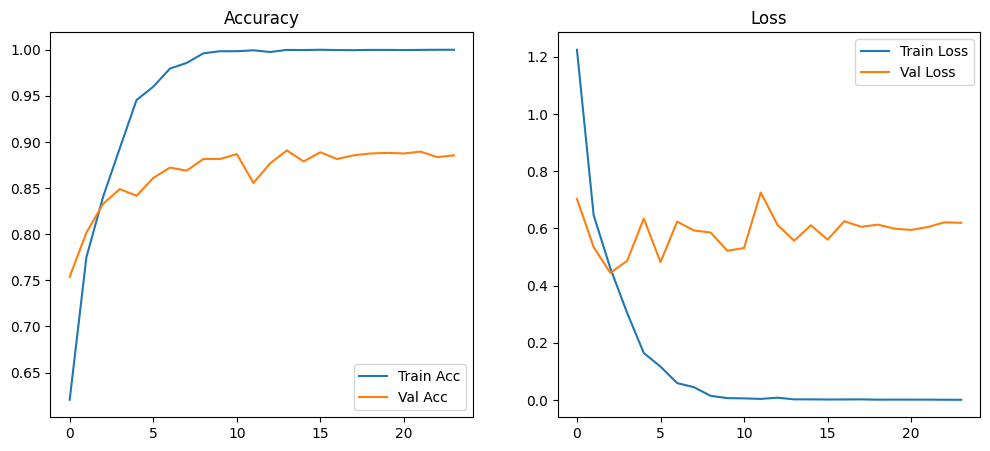

In [4]:
# ================================================================
# Training curves
# ================================================================
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Accuracy")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.legend()
plt.show()

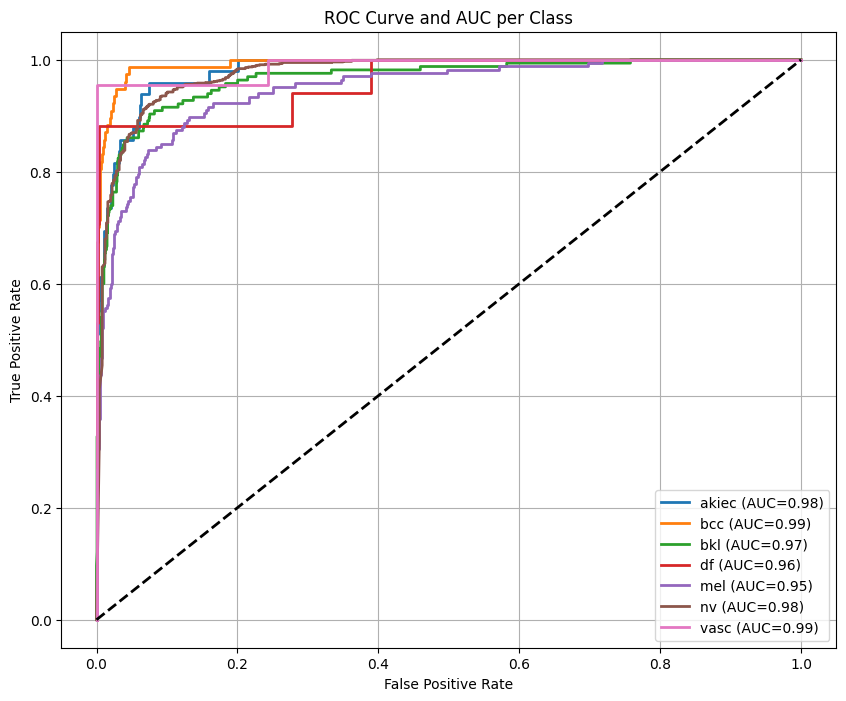

AUC for akiec: 0.981
AUC for bcc: 0.993
AUC for bkl: 0.966
AUC for df: 0.960
AUC for mel: 0.948
AUC for nv: 0.976
AUC for vasc: 0.989
weighted-average AUC: 0.987


In [5]:
# ================================================================
# ROC Curves - Safe Version
# ================================================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def collect_predictions_for_roc(generator, model, num_batches=None):
    """Collect predictions from generator safely for ROC"""
    y_true_list = []
    y_pred_list = []
    
    n_batches = len(generator)
    if num_batches is not None:
        n_batches = min(n_batches, n_batches)
    
    if n_batches == 0:
        print(" Warning: Generator has no batches!")
        return np.array([]), np.array([])
    
    for i in range(n_batches):
        try:
            batch_x, batch_y = generator[i]
            
            if isinstance(batch_x, tuple):
                batch_pred = model.predict(batch_x, verbose=0)
            else:
                batch_pred = model.predict(batch_x, verbose=0)
            
            y_true_list.append(batch_y)
            y_pred_list.append(batch_pred)
            
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not y_true_list:
        print(" No predictions collected!")
        return np.array([]), np.array([])
    
    return np.concatenate(y_true_list, axis=0), np.concatenate(y_pred_list, axis=0)

y_true, y_pred = collect_predictions_for_roc(test_gen, model)

if y_true.size == 0 or y_pred.size == 0:
    print(" Failed to collect predictions, skipping ROC Curves")
else:
    if y_true.ndim == 2:
        y_true_indices = np.argmax(y_true, axis=1)
    else:
        y_true_indices = y_true

    n_classes = y_pred.shape[1]
    class_names = le.classes_

    y_true_bin = label_binarize(y_true_indices, classes=range(n_classes))

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fpr["weighted"], tpr["weighted"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
    roc_auc["weighted"] = auc(fpr["weighted"], tpr["weighted"])

    plt.figure(figsize=(10, 8))
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], lw=2, label=f"{class_names[i]} (AUC={roc_auc[i]:.2f})")

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve and AUC per Class")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    for i in range(n_classes):
        print(f"AUC for {class_names[i]}: {roc_auc[i]:.3f}")
    print(f"weighted-average AUC: {roc_auc['weighted']:.3f}")

In [6]:
# ================================================================
# Complete Metrics
# ================================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

precision = precision_score(true_labels, pred_labels, average="weighted")
sensitivity = recall_score(true_labels, pred_labels, average="weighted")
f1 = f1_score(true_labels, pred_labels, average="weighted")

cm = confusion_matrix(true_labels, pred_labels)
TN = []
FP = []
for i in range(len(cm)):
    tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
    fp = np.sum(cm[:, i]) - cm[i, i]
    TN.append(tn)
    FP.append(fp)
specificity = np.mean(np.array(TN) / (np.array(TN) + np.array(FP)))

auc_score = roc_auc_score(true_labels, preds, multi_class="ovr", average="weighted")

print("="*50)
print(" COMPLETE METRICS SUMMARY")
print("="*50)
print(f" Accuracy    : {acc*100:.2f}%")
print(f" Specificity : {specificity*100:.2f}%")
print(f" Precision   : {precision*100:.2f}%")
print(f" Sensitivity : {sensitivity*100:.2f}%")
print(f" F1 Score    : {f1*100:.2f}%")
print("="*50)

 COMPLETE METRICS SUMMARY
 Accuracy    : 87.69%
 Specificity : 96.52%
 Precision   : 87.28%
 Sensitivity : 87.69%
 F1 Score    : 87.31%



 GradCAM Visualization

 Model Layers (for GradCAM):
----------------------------------------
   1: convnext_tiny_prestem_normalization - Normalization
   2: convnext_tiny_stem - Sequential
   3: convnext_tiny_stage_0_block_0_depthwise_conv - Conv2D
   4: convnext_tiny_stage_0_block_0_layernorm - LayerNormalization
   5: convnext_tiny_stage_0_block_0_pointwise_conv_1 - Dense
   6: convnext_tiny_stage_0_block_0_gelu - Activation
   7: convnext_tiny_stage_0_block_0_pointwise_conv_2 - Dense
   8: convnext_tiny_stage_0_block_0_layer_scale - LayerScale
   9: convnext_tiny_stage_0_block_0_identity - Activation
   10: convnext_tiny_stage_0_block_1_depthwise_conv - Conv2D
   ... and more

 Testing GradCAM on a sample image
 Image: ISIC_0034198.jpg

 Trying layer: Auto-detect
 Using layer: convnext_tiny_stage_3_block_2_identity


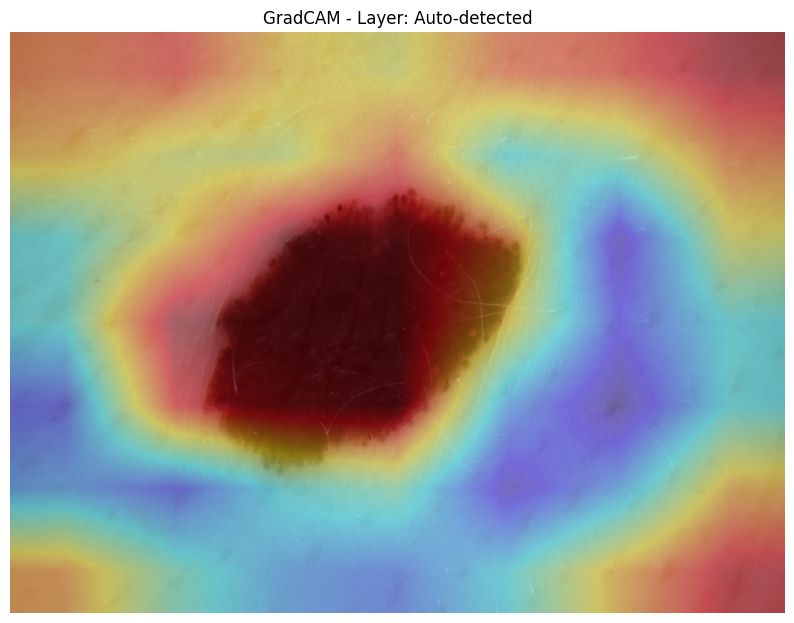


 GradCAM Grid on multiple images
 Using layer: convnext_tiny_stage_3_block_2_identity
 Using layer: convnext_tiny_stage_3_block_2_identity
 Using layer: convnext_tiny_stage_3_block_2_identity
 Using layer: convnext_tiny_stage_3_block_2_identity
 Using layer: convnext_tiny_stage_3_block_2_identity
 Using layer: convnext_tiny_stage_3_block_2_identity


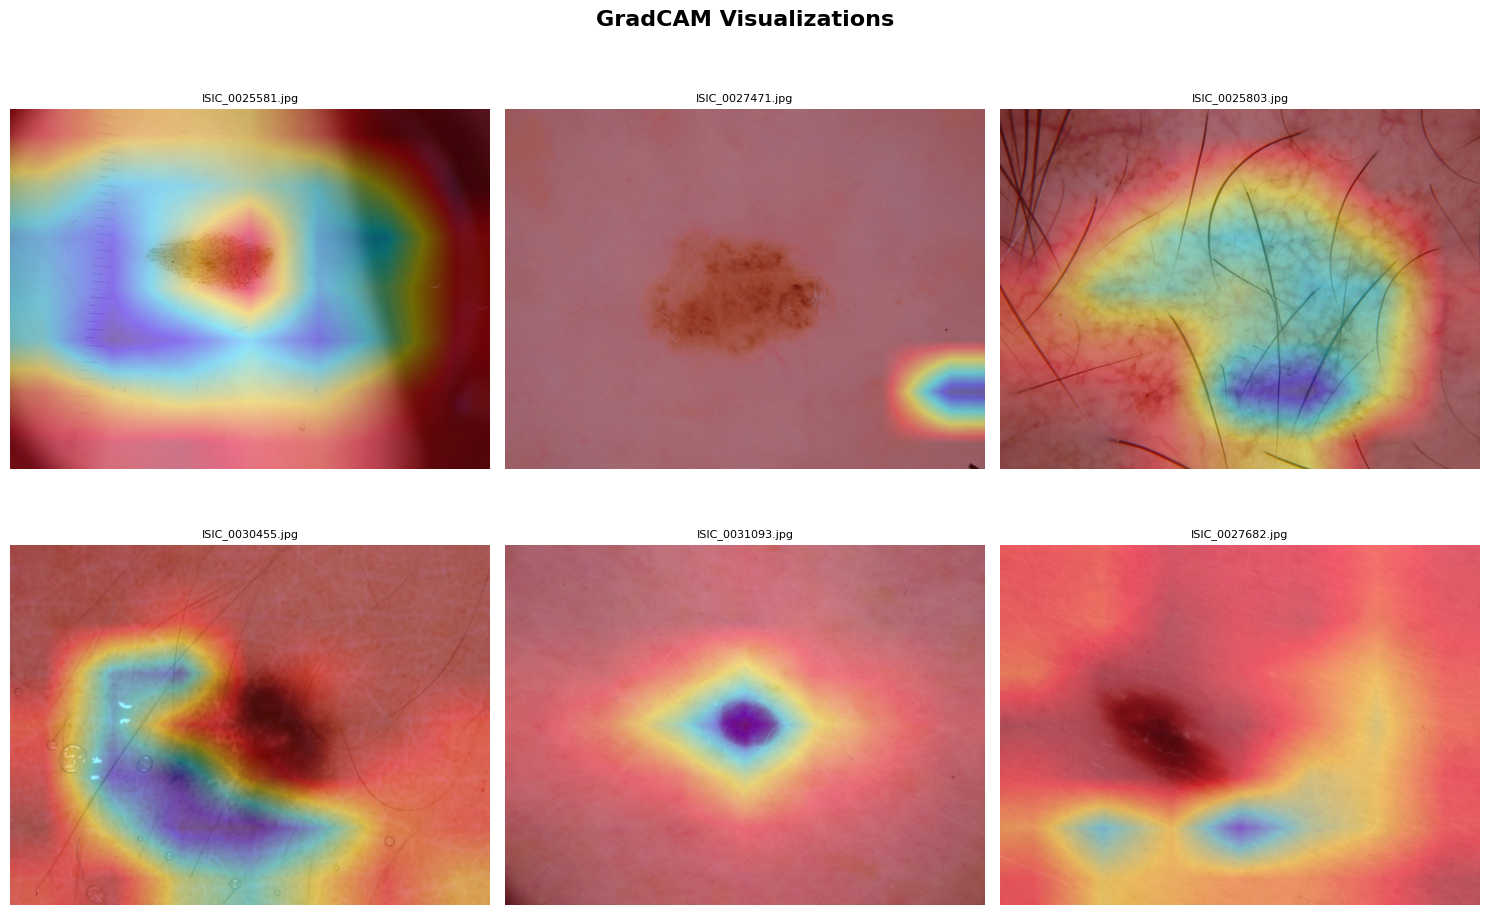


 GradCAM visualization complete!


NameError: name 'USE_HANCRAFTED' is not defined

In [7]:
# ================================================================
# Cell 19: GradCAM Functions (Enhanced)
# ================================================================
from tensorflow.keras.applications.convnext import preprocess_input as convnext_preprocess
def get_gradcam_heatmap(model, img_array, layer_name=None, pred_index=None, hand_features=None):
    """
    Generate GradCAM heatmap with automatic layer selection
    """
    # If no layer is specified, find the best Conv layer
    if layer_name is None:
        for layer in reversed(model.layers):
            # Look for suitable Conv layers
            if 'conv' in layer.name and 'convnext' in layer.name:
                layer_name = layer.name
                break
            elif 'conv' in layer.name and 'block' in layer.name:
                layer_name = layer.name
                break
            elif 'conv2d' in layer.name.lower():
                layer_name = layer.name
                break
        
        # If no layer found, use the last Conv layer
        if layer_name is None:
            for layer in reversed(model.layers):
                if 'conv' in layer.name.lower():
                    layer_name = layer.name
                    break
    
    print(f" Using layer: {layer_name}")
    
    try:
        # Try to create the model with the specified layer
        grad_model = tf.keras.models.Model(
            inputs=model.inputs,
            outputs=[model.get_layer(layer_name).output, model.output]
        )
    except Exception as e:
        print(f" Error with layer {layer_name}: {e}")
        # Try using an alternative layer
        for layer in reversed(model.layers):
            if 'conv' in layer.name.lower():
                try:
                    grad_model = tf.keras.models.Model(
                        inputs=model.inputs,
                        outputs=[layer.output, model.output]
                    )
                    layer_name = layer.name
                    print(f" Using alternative layer: {layer_name}")
                    break
                except:
                    continue
    
    # Prepare inputs
    inputs = [img_array]
    if hand_features is not None:
        inputs.append(hand_features)
    
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(inputs)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        loss = predictions[:, pred_index]
    
    grads = tape.gradient(loss, conv_outputs)
    
    # Process gradients
    if grads is None:
        print(" No gradients found. Using fallback method.")
        # Use alternative method
        heatmap = np.random.rand(7, 7)  # Random size
        return heatmap
    
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    
    # Normalize heatmap
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()


def display_gradcam(img_path, model, layer_name=None, alpha=0.4, hand_features=None):
    """
    Display image with GradCAM overlay with automatic layer detection
    """
    # Load and process image
    img = cv2.imread(img_path)
    if img is None:
        print(f" Cannot read image: {img_path}")
        return None
    
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img_preprocessed = convnext_preprocess(img_resized.astype(np.float32))
    img_array = np.expand_dims(img_preprocessed, axis=0)
    
    try:
        # Try to get the heatmap
        if hand_features is not None:
            heatmap = get_gradcam_heatmap(model, img_array, layer_name, hand_features=hand_features)
        else:
            heatmap = get_gradcam_heatmap(model, img_array, layer_name)
        
        # Resize heatmap to match original image
        heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
        heatmap_resized = np.uint8(255 * heatmap_resized)
        heatmap_colored = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)
        
        # Overlay image with heatmap
        superimposed_img = cv2.addWeighted(img, 1 - alpha, heatmap_colored, alpha, 0)
        return superimposed_img
    
    except Exception as e:
        print(f" Cannot generate GradCAM: {e}")
        print(" Attempting to find suitable layers...")
        
        # Display all available layers
        print("\n Available layers in model:")
        for i, layer in enumerate(model.layers):
            if 'conv' in layer.name.lower():
                print(f"   {i}: {layer.name} - {layer.__class__.__name__}")
        
        return img


def display_gradcam_grid(images_paths, model, layer_name=None, grid_cols=3, hand_features=None):
    """
    Display multiple GradCAM visualizations in a grid
    """
    n_images = len(images_paths)
    grid_rows = (n_images + grid_cols - 1) // grid_cols
    
    fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(grid_cols * 5, grid_rows * 5))
    fig.suptitle(f'GradCAM Visualizations', fontsize=16, fontweight='bold')
    
    # If there's only one row
    if grid_rows == 1:
        axes = axes.reshape(1, -1)
    
    results = []
    
    for idx, img_path in enumerate(images_paths):
        row = idx // grid_cols
        col = idx % grid_cols
        ax = axes[row, col]
        
        try:
            # Display GradCAM
            if hand_features is not None:
                result_img = display_gradcam(img_path, model, layer_name, hand_features=hand_features)
            else:
                result_img = display_gradcam(img_path, model, layer_name)
            
            if result_img is not None:
                ax.imshow(result_img)
                
                # Add filename
                filename = os.path.basename(img_path)
                ax.set_title(filename[:20], fontsize=8)
            else:
                ax.text(0.5, 0.5, 'Error', ha='center', va='center')
            
            ax.axis('off')
            results.append(result_img)
            
        except Exception as e:
            print(f" Error processing {img_path}: {e}")
            ax.text(0.5, 0.5, 'Error', ha='center', va='center')
            ax.axis('off')
    
    # Hide empty subplots
    for idx in range(len(images_paths), grid_rows * grid_cols):
        row = idx // grid_cols
        col = idx % grid_cols
        axes[row, col].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    return results


# ================================================================
# Cell 20: Visualize GradCAM on Sample Images
# ================================================================

print("\n" + "="*60)
print(" GradCAM Visualization")
print("="*60)

#  Display all available layers in the model
print("\n Model Layers (for GradCAM):")
print("-" * 40)
conv_layers = []
for i, layer in enumerate(model.layers):
    if 'conv' in layer.name.lower():
        conv_layers.append(layer.name)
        print(f"   {i}: {layer.name} - {layer.__class__.__name__}")
        if len(conv_layers) >= 10:  # Display only first 10 layers
            print("   ... and more")
            break

#  Select appropriate layer
# Try different layers
layer_options = [
    None,  # Auto
    'convnext_tiny_stage_3_block_2_pointwise_conv_2',
    'convnext_tiny_stage_4_block_1_pointwise_conv_2',
    'convnext_tiny_stage_2_block_2_pointwise_conv_2',
]

#  Test on a single image
print("\n" + "="*60)
print(" Testing GradCAM on a sample image")
print("="*60)

sample_img_path = test_df['path'].iloc[0]
print(f" Image: {os.path.basename(sample_img_path)}")

# Try with different layers
for layer_name in layer_options[:2]:  # Try first two layers
    try:
        print(f"\n Trying layer: {layer_name if layer_name else 'Auto-detect'}")
        gradcam_result = display_gradcam(sample_img_path, model, layer_name=layer_name)
        
        if gradcam_result is not None:
            plt.figure(figsize=(10, 8))
            plt.imshow(gradcam_result)
            plt.title(f'GradCAM - Layer: {layer_name if layer_name else "Auto-detected"}', fontsize=12)
            plt.axis('off')
            plt.show()
            break
    except Exception as e:
        print(f" Failed with layer {layer_name}: {e}")

#  Display GradCAM on a grid of images
print("\n" + "="*60)
print(" GradCAM Grid on multiple images")
print("="*60)

# Select 6 images from test data
num_test_images = min(6, len(test_df))
test_images = test_df['path'].sample(num_test_images, random_state=42).values

results = display_gradcam_grid(
    images_paths=test_images,
    model=model,
    layer_name=None,  # Auto
    grid_cols=3
)

print("\n" + "="*60)
print(" GradCAM visualization complete!")
print("="*60)


# ================================================================
# (Optional) Try GradCAM with Handcrafted Features
# ================================================================
if USE_HANCRAFTED:
    print("\n" + "="*60)
    print(" GradCAM with Handcrafted Features")
    print("="*60)
    
    # Extract handcrafted features
    hand_features = extract_handcrafted_features(sample_img_path)
    hand_features = np.expand_dims(hand_features, axis=0)
    
    gradcam_result = display_gradcam(
        sample_img_path, 
        model, 
        layer_name=None, 
        hand_features=hand_features
    )
    
    if gradcam_result is not None:
        plt.figure(figsize=(10, 8))
        plt.imshow(gradcam_result)
        plt.title('GradCAM with Handcrafted Features', fontsize=12)
        plt.axis('off')
        plt.show()
